# Agglomerative clustering
Agglomerative clustering es un metodo jerarquico el cual va uniendo clusteres de forma sucesiva:
Cada punto inicia como un solo cluster y en cada paso se fusionan los clusteres más cercanos usando un criterio de enlace `linkage`.

Trabajaremos con datos sinteticos generados por `make_blobs` para estudiar el comportamiento de este metodo de clustering en una estructura sencilla y controlada. Támbien se usaran las metricas de evaluación `homogeneidad` `completitud` `V measure`.

In [69]:
from sklearn.datasets import make_blobs
from sklearn.cluster import AgglomerativeClustering
from sklearn.model_selection import train_test_split
from sklearn.metrics import homogeneity_completeness_v_measure

import numpy as np
import matplotlib.pyplot as plt


### Datos artificales con 3 centros 

/var/folders/6f/cl93v53x4kvg964cp1lrrmp40000gn/T/ipykernel_8929/1370062744.py:6: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


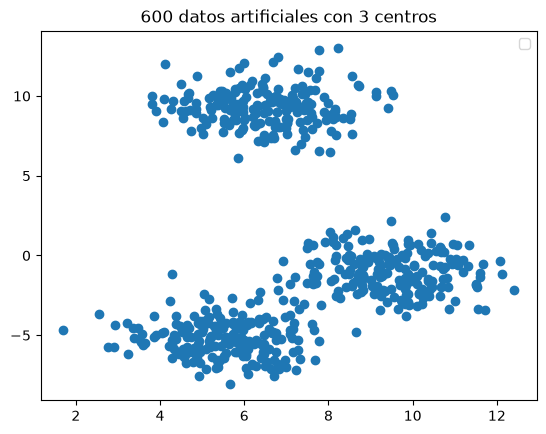

In [62]:
X, y = make_blobs(n_samples=600, centers=3, n_features=2, cluster_std=1.2 ,random_state=13)

plt.figure()
plt.title('600 datos artificiales con 3 centros')
plt.scatter(X[:, 0], X[:, 1])
plt.legend()
plt.show()

### Aplicacion de agglomerative clustering

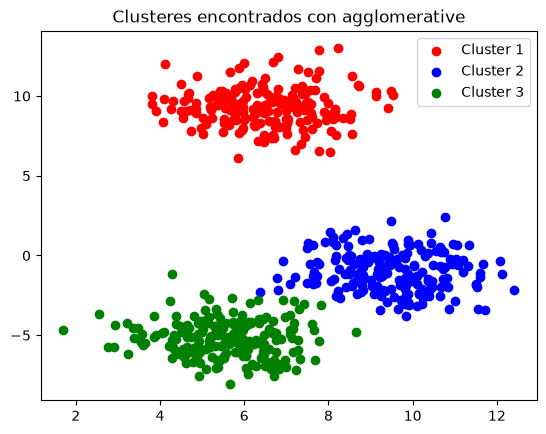

In [63]:
#instanciar y entrenar 
agg = AgglomerativeClustering(n_clusters=3, linkage='ward')
agg.fit(X)
labels1 = agg.labels_

colores = ['red', 'blue', 'green']
plt.figure()
plt.title('Clusteres encontrados con agglomerative')

for label in (np.unique(labels1)):
    mascara = labels1 == label
    plt.scatter(X[mascara, 0], X[mascara, 1], color = colores[label], label = f'Cluster {label+1}')

plt.legend()
plt.show()


Podemos notar que nuestro modelo si encuentras la estructura real de los datos y los particiona de forma correcta (usando los clusteres que le dimos de un inicio).
Aunque agglomerative funciona pasando desde $n$ clusteres hasta $1$, en este caso se queda en la cantidad que le pedimos. Para observar ese proceso usaremos una porcion de los datos y veremos en dendograma.

In [64]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5, random_state=42, stratify=y)

## Dendograma 

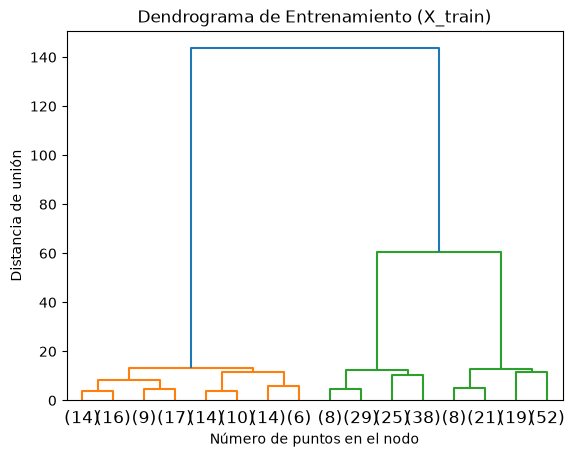

In [65]:

from scipy.cluster.hierarchy import dendrogram

modelo = AgglomerativeClustering(distance_threshold=0, n_clusters=None)
modelo.fit(X_train)

#funcion para visualizar el dendrograma
def plot_dendrogram(model, **kwargs):
    
    counts = np.zeros(model.children_.shape[0])
    n_samples = len(model.labels_)
    for i, merge in enumerate(model.children_):
        current_count = 0
        for child_idx in merge:
            if child_idx < n_samples:
                current_count += 1  # Nodo hoja
            else:
                current_count += counts[child_idx - n_samples]
        counts[i] = current_count


    linkage_matrix = np.column_stack(
        [model.children_, model.distances_, counts]
    ).astype(float)

    # Dibujar el dendrograma
    dendrogram(linkage_matrix, **kwargs)

# visualización
plt.figure()
plt.title("Dendrograma de Entrenamiento (X_train)")

plot_dendrogram(modelo, truncate_mode="level", p=3)

plt.xlabel("Número de puntos en el nodo")
plt.ylabel("Distancia de unión")
plt.show()

Podemos notar que los datos de entrenamiento tambien nos indican un corte en $K=3$ clusteres pues es donde mayor es la altura vestical de las distancias (es decir que ahi ya no cambian tanto los clusteres)
Cada hoja los va representando los clusteres que hay en cada momento y podemos ir viendo como se van uniendo entre ellos hasta llegar al cluster unico.
Con el dendograma podemos ayudarnos a decidir el numero de clusteres que vamos a usar pues cuando la altura es muy grande, podemos hacer un corte pues apartir de ese momento ya no nos está aportando mucho el seguir uniendo. 


## Criterio de enlace
Existen varios tipos de enlace para medir las distancias entre clusteres y dependiendo del problema, es cual enlace vamos a ocupar. Vamos a comparar los mismos datos usando 4 enlaces.

*   **Single linkage**
    La distancia mínima entre el cluster $C_i$ y $C_j$:
    $$ L_{single}(C_i, C_j) = \min \{ d(a,b) \mid a \in C_i, b \in C_j \} $$

*   **Complete linkage**
    La distancia máxima:
    $$ L_{complete}(C_i, C_j) = \max \{ d(a,b) \mid a \in C_i, b \in C_j \} $$
    *Favorece clústeres compactos y de diámetro pequeño.*

*   **Average linkage**
    El promedio de las distancias:
    $$ L_{average}(C_i, C_j) = \frac{1}{|C_i| |C_j|} \sum_{a \in C_i, b \in C_j} d(a,b) $$

*   **Centroid linkage**
    Distancia entre centroides:
    $$ L_{centroid}(C_i, C_j) = d(\mu_i, \mu_j) $$
    *(Donde $\mu$ es el centroide).*

*   **Ward**
    Fusiona el par que menos aumenta la inercia intra-cluster.

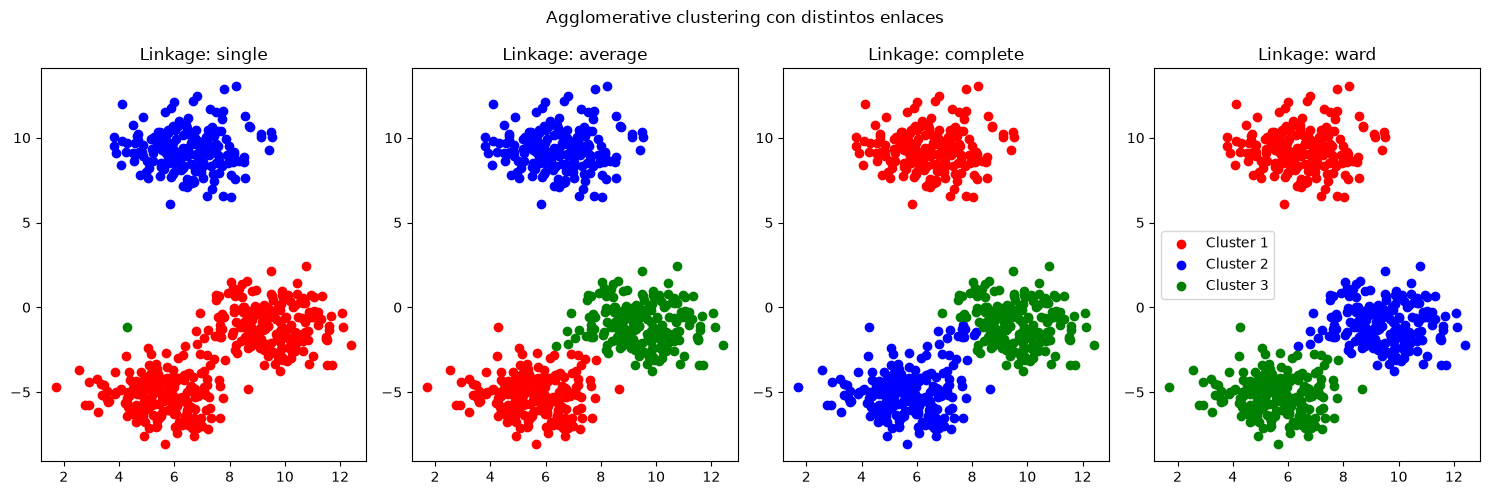

In [68]:
#enlaces a usar 
enlaces = ['single', 'average', 'complete', 'ward']
fig, ax = plt.subplots(1, 4, figsize=(15, 5))
fig.suptitle('Agglomerative clustering con distintos enlaces')

for i, enlace in enumerate(enlaces):

    agg = AgglomerativeClustering(n_clusters=3, linkage=enlace)
    agg.fit(X)
    labels = agg.labels_

    colores = ['red', 'blue', 'green']

    for label in (np.unique(labels)):
        mascara = labels == label
        ax[i].scatter(X[mascara, 0], X[mascara, 1], color = colores[label], label = f'Cluster {label+1}')
    
    ax[i].set_title(f'Linkage: {enlace}')
ax[-1].legend()


plt.tight_layout()
plt.show()



Podemos notar que no todos los enlaces nos producen la misma agrupación; `single` nos devuelve 2 clusteres bien formados y un cluster de un solo punto, mientras que los demas enlaces si nos devuelven la misma cantidad de clusteres y estructuras muy parecidas solo discrepando en unos cuantos puntos.

Para hacer la comparación mantuvimos constante todos parametros pues sino pueden influir en los resultados y alterar la comparación. 


## Evaluación de metricas 
Vamos a evaluar las metricas `homogeneidad`, `completitud` y `V measure` en el modelo de agglomerative usando los enlaces `single` y `complete` pues son dos que tienen diferencias. 

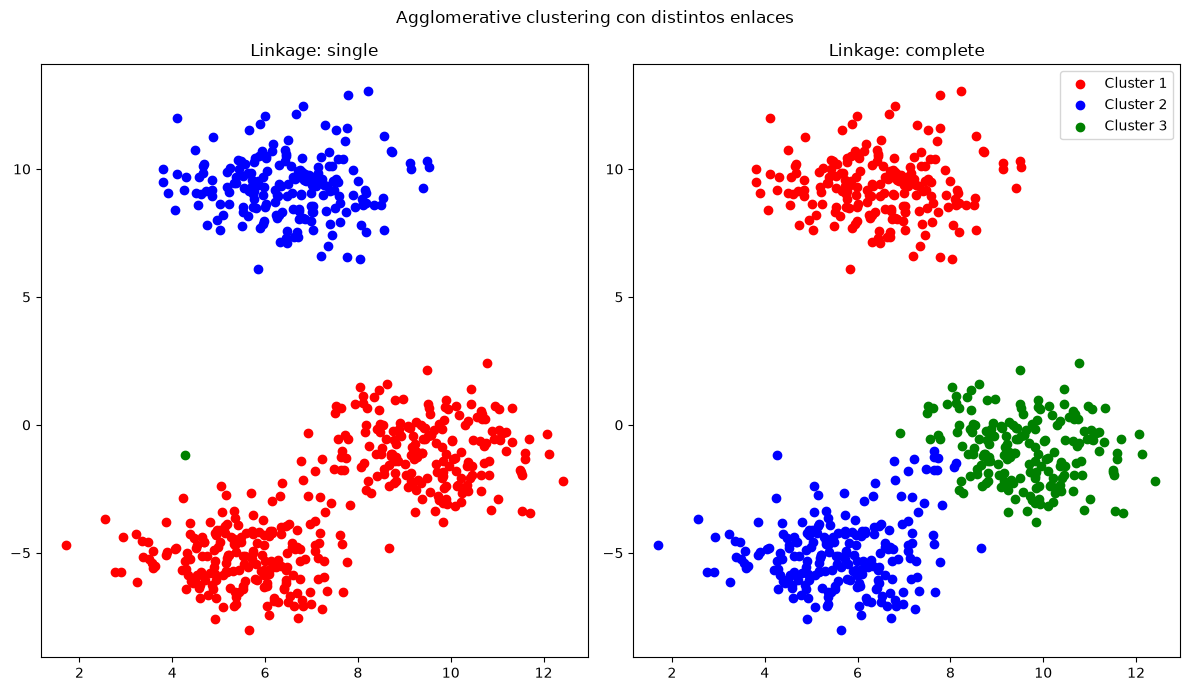

,Métrica,Enlace single,Enlace complete
0,Homogeneidad,0.580434,0.913474
1,Completitud,0.983811,0.915253
2,V-Measure,0.730112,0.914363


In [82]:
import pandas as pd
resultados = {
    'Métrica': ['Homogeneidad', 'Completitud', 'V-Measure'],
    'Enlace single': [],
    'Enlace complete': []
}

enlaces = ['single', 'complete']
fig, ax = plt.subplots(1, 2, figsize=(12, 7))
fig.suptitle('Agglomerative clustering con distintos enlaces')

for i, enlace in enumerate(enlaces):

    agg = AgglomerativeClustering(n_clusters=3, linkage=enlace)
    agg.fit(X)
    labels = agg.labels_
    if i == 0: 
        resultados['Enlace single'] = list(homogeneity_completeness_v_measure(y, labels))

    elif i == 1:
        resultados['Enlace complete'] = list(homogeneity_completeness_v_measure(y, labels))

    colores = ['red', 'blue', 'green']

    for label in (np.unique(labels)):
        mascara = labels == label
        ax[i].scatter(X[mascara, 0], X[mascara, 1], color = colores[label], label = f'Cluster {label+1}')
    
    ax[i].set_title(f'Linkage: {enlace}')
ax[-1].legend()

plt.tight_layout()
plt.show()
dt = pd.DataFrame(resultados)
display(dt)



Podemos notar que efectivamente el enlace single tiene una mala metrica de homogeneidad pues no agrupa bien los puntos de una misma clase. Esto nos confirma lo que observabamos en las graficas, mientras que el enlace complete tiene mejores metricas tal como lo observamos.

### Reflexión 
La idea principal de agglomerative clustering es crear una familia de clusteres en el que no tengamos que fijar el numero de antemano sino poder ver como va evolucionando el proceso y con eso poder ver cual es el numero conveniente. En el dendograma podemos ver ese proceso de evolución. 
La diferencia entre este algoritmo y otros como kmeans y dbscan es que funciona de forma distinta, es determinista y nos permite ver toda la familia de distintos clusteres. 